In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [86]:
# Load cleaned jobs
jobs = pd.read_csv("../data/processed/jobs_cleaned.csv")

# Load the new 4,000-user interaction dataset
interactions = pd.read_csv(
    "../data/processed/user_interactions_v2.csv"
)

# Ensure consistent data types
jobs['id'] = jobs['id'].astype(int)
interactions['job_id'] = interactions['job_id'].astype(int)

# Display dataset information
print("JOBS DATASET")
print("=" * 40)
print("Shape:", jobs.shape)

print("\nNEW INTERACTION DATASET")
print("=" * 40)
print("Shape:", interactions.shape)
print("Unique users:", interactions['user_id'].nunique())
print("Unique jobs:", interactions['job_id'].nunique())

print("\nINTERACTION DISTRIBUTION")
print(interactions['interaction_type'].value_counts())

print("\nINTERACTION PERCENTAGES")
print(
    interactions['interaction_type']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nRATING DISTRIBUTION")
print(interactions['rating'].value_counts().sort_index())

JOBS DATASET
Shape: (1020, 13)

NEW INTERACTION DATASET
Shape: (80224, 6)
Unique users: 4000
Unique jobs: 1020

INTERACTION DISTRIBUTION
interaction_type
save     33803
view     32650
apply    13771
Name: count, dtype: int64

INTERACTION PERCENTAGES
interaction_type
save     42.14
view     40.70
apply    17.17
Name: proportion, dtype: float64

RATING DISTRIBUTION
rating
1    32650
3    33803
5    13771
Name: count, dtype: int64


In [87]:
print("Number of jobs:", jobs['id'].nunique())

print("\nEmployment types:")
print(jobs['employment_type'].value_counts())

print("\nAvailable columns:")
print(jobs.columns.tolist())

Number of jobs: 1020

Employment types:
employment_type
Full-time     807
Internship    106
Contract       75
Part-time      24
Temporary       5
Unknown         3
Name: count, dtype: int64

Available columns:
['id', 'title', 'company', 'location', 'salary_range', 'workplace_type', 'employment_type', 'description', 'clean_description', 'extracted_skills', 'all_skills', 'technical_skills', 'professional_skills']


**Prepare the job skills**

In [88]:
import ast

# Convert technical skills from strings into Python lists
jobs['technical_skills'] = jobs['technical_skills'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else x
)

# Create a text representation of technical skills
jobs['skills_text'] = jobs['technical_skills'].apply(
    lambda skills: ' '.join(skills)
)

print("Technical skills prepared successfully!")

jobs[['title', 'company', 'technical_skills']].head()

Technical skills prepared successfully!


,title,company,technical_skills
0,Machine Learning Engineering Internship - Summer 2026,Viant Technology,"[python, sql, machine learning, artificial intelligence, data science, data pipelines, tensorflo..."
1,NVIDIA 2026 Internships: Deep Learning Computer Architecture - US,NVIDIA,"[python, c++, deep learning, neural networks, tensorflow, pytorch, keras, computer architecture,..."
2,Summer 2026 Intern - Undergrad User Research - Slack,Salesforce,"[artificial intelligence, statistics]"
3,Summer 2026 Engineering Intern,Truveta,"[python, java, c#, big data]"
4,Applied AI Engineer (Internship),Fortinet,"[python, go, generative ai, cybersecurity]"


**User–job interaction matrix**

In [89]:
user_job_matrix = interactions.pivot_table(
    index='user_id',
    columns='job_id',
    values='rating',
    fill_value=0
)

print("USER-JOB INTERACTION MATRIX")
print("=" * 50)

print("Matrix shape:", user_job_matrix.shape)
print("Number of users:", user_job_matrix.shape[0])
print("Number of jobs:", user_job_matrix.shape[1])

# Calculate matrix sparsity
total_possible = (
    user_job_matrix.shape[0] *
    user_job_matrix.shape[1]
)

non_zero = np.count_nonzero(user_job_matrix.values)

sparsity = (1 - non_zero / total_possible) * 100

print("Non-zero interactions:", non_zero)
print("Matrix sparsity:", round(sparsity, 2), "%")

print("\nMatrix preview:")
display(user_job_matrix.iloc[:5, :10])

USER-JOB INTERACTION MATRIX
Matrix shape: (4000, 1020)
Number of users: 4000
Number of jobs: 1020
Non-zero interactions: 80224
Matrix sparsity: 98.03 %

Matrix preview:


job_id,1,2,3,4,5,6,7,8,9,10
user_id,,,,,,,,,,
USER_001,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
USER_002,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
USER_003,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
USER_004,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
USER_005,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [90]:
# Calculate similarity between users

user_similarity = cosine_similarity(user_job_matrix)

# Convert similarity scores into a DataFrame
user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_job_matrix.index,
    columns=user_job_matrix.index
)

print("User similarity calculated successfully!")
print("Similarity matrix shape:", user_similarity_df.shape)

user_similarity_df.head()

User similarity calculated successfully!
Similarity matrix shape: (4000, 4000)


user_id   USER_001  USER_002  USER_003  USER_004  USER_005  USER_006  \
user_id                                                                
USER_001  1.000000  0.024308  0.231284  0.019288  0.000000  0.065611   
USER_002  0.024308  1.000000  0.326490  0.245049  0.062539  0.000000   
USER_003  0.231284  0.326490  1.000000  0.333087  0.039670  0.000000   
USER_004  0.019288  0.245049  0.333087  1.000000  0.049624  0.000000   
USER_005  0.000000  0.062539  0.039670  0.049624  1.000000  0.000000   

user_id   USER_007  USER_008  USER_009  USER_010  USER_011  USER_012  \
user_id                                                                
USER_001  0.105791       0.0  0.000000  0.000000  0.000000  0.553206   
USER_002  0.019201       0.0  0.000000  0.000000  0.102220  0.000000   
USER_003  0.000000       0.0  0.006159  0.005671  0.000000  0.179127   
USER_004  0.025393       0.0  0.000000  0.000000  0.000000  0.018673   
USER_005  0.000000       0.0  0.000000  0.007604  0.376746  0.000000   

user_id   USER_013  USER_014  USER_015  USER_016  USER_017  USER_018  \
user_id                                                                
USER_001  0.102827  0.545349  0.620637  0.000000  0.030218  0.000000   
USER_002  0.223953  0.000000  0.000000  0.011562  0.054845  0.142090   
USER_003  0.347254  0.211949  0.099934  0.007334  0.000000  0.140203   
USER_004  0.256685  0.045023  0.018751  0.009175  0.000000  0.563735   
USER_005  0.000000  0.000000  0.000000  0.137679  0.000000  0.201419   

user_id   USER_019  USER_020  USER_021  USER_022  USER_023  USER_024  \
user_id                                                                
USER_001  0.000000  0.017580  0.000000  0.072049  0.149448  0.430559   
USER_002  0.000000  0.361620  0.000000  0.052307  0.052926  0.009648   
USER_003  0.025731  0.222638  0.006081  0.000000  0.012589  0.257026   
USER_004  0.024140  0.346019  0.000000  0.000000  0.015749  0.252623   
USER_005  0.025876  0.000000  0.000000  0.000000  0.084403  0.000000   

user_id   USER_025  USER_026  USER_027  USER_028  USER_029  USER_030  \
user_id                                                                
USER_001  0.000000  0.144840       0.0  0.000000  0.000000  0.000000   
USER_002  0.000000  0.000000       0.0  0.000000  0.155268  0.000000   
USER_003  0.061588  0.014713       0.0  0.125895  0.000000  0.014480   
USER_004  0.000000  0.000000       0.0  0.000000  0.000000  0.000000   
USER_005  0.000000  0.000000       0.0  0.000000  0.382974  0.019415   

user_id   USER_031  USER_032  USER_033  USER_034  USER_035  USER_036  \
user_id                                                                
USER_001  0.096291  0.084662  0.000000  0.493771       0.0  0.000000   
USER_002  0.194184  0.081349  0.000000  0.021004       0.0  0.000000   
USER_003  0.363368  0.338277  0.000000  0.226499       0.0  0.000000   
USER_004  0.130971  0.337093  0.000000  0.133333       0.0  0.000000   
USER_005  0.206449  0.115316  0.341337  0.000000       0.0  0.021455   

user_id   USER_037  USER_038  USER_039  USER_040  USER_041  USER_042  \
user_id                                                                
USER_001  0.000000  0.000000  0.074011       0.0  0.000000  0.146425   
USER_002  0.000000  0.014193  0.033582       0.0  0.000000  0.030902   
USER_003  0.000000  0.000000  0.012781       0.0  0.000000  0.000000   
USER_004  0.000000  0.000000  0.015988       0.0  0.000000  0.000000   
USER_005  0.020315  0.000000  0.017138       0.0  0.189451  0.000000   

user_id   USER_043  USER_044  USER_045  USER_046  USER_047  USER_048  \
user_id                                                                
USER_001  0.075405  0.019469  0.173308  0.602923       0.0  0.080729   
USER_002  0.000000  0.176679  0.195237  0.022181       0.0  0.007326   
USER_003  0.000000  0.276443  0.529776  0.196983       0.0  0.000000   
USER_004  0.006787  0.476656  0.309839  0.052803       0.0  0.000000   
USER_005  0.000000  0.030054  0.0

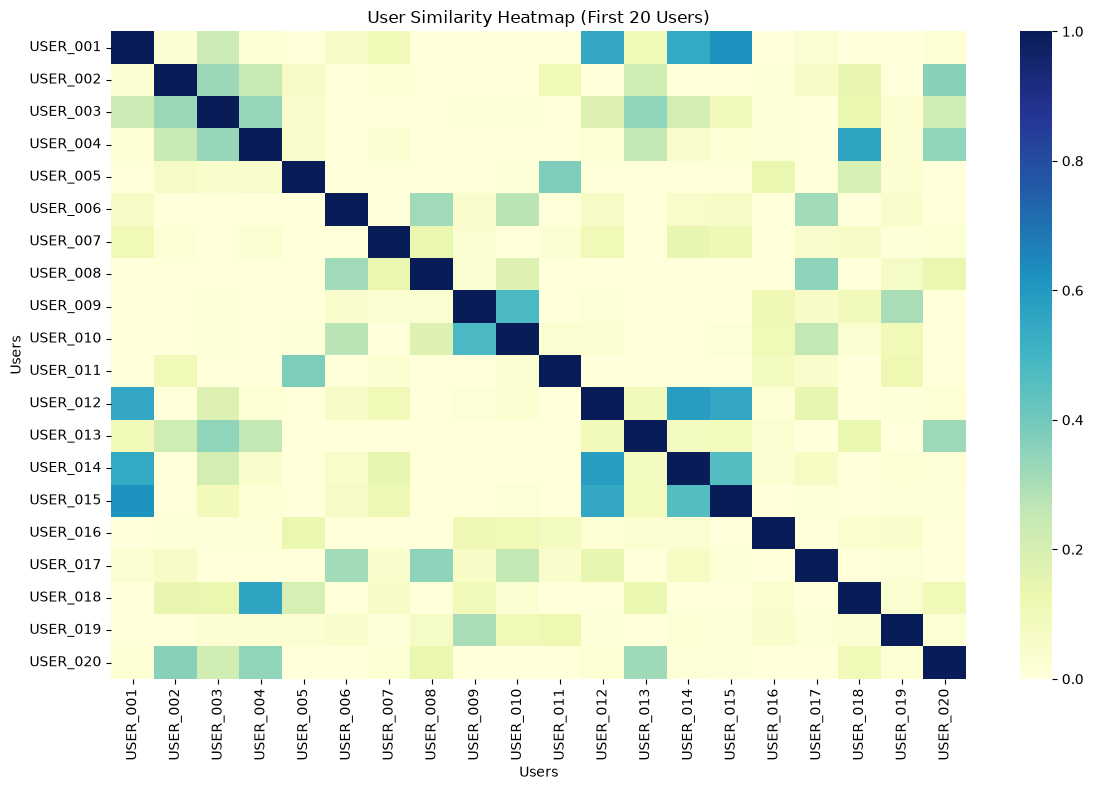

In [91]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    user_similarity_df.iloc[:20, :20],
    cmap='YlGnBu'
)

plt.title('User Similarity Heatmap (First 20 Users)')
plt.xlabel('Users')
plt.ylabel('Users')
plt.tight_layout()
plt.show()

In [92]:
# Find the most similar users to USER_001

target_user = 'USER_001'

similar_users = user_similarity_df[target_user].drop(target_user)

top_similar_users = similar_users.sort_values(
    ascending=False
).head(5)

print(f"TOP 5 USERS SIMILAR TO {target_user}")
print("=" * 50)

display(
    top_similar_users.reset_index().rename(
        columns={
            'user_id': 'similar_user',
            'USER_001': 'similarity_score'
        }
    )
)

TOP 5 USERS SIMILAR TO USER_001


,similar_user,similarity_score
0,USER_1684,0.776070
1,USER_1560,0.757269
2,USER_1041,0.708514
3,USER_1543,0.697373
4,USER_3922,0.696115


**Inspect the similarity scores**

In [93]:
# Exclude each user's similarity with themselves
similarity_values = user_similarity.copy()
np.fill_diagonal(similarity_values, np.nan)

print("Average user similarity:",
      np.nanmean(similarity_values))

print("Highest user similarity:",
      np.nanmax(similarity_values))

print("Lowest user similarity:",
      np.nanmin(similarity_values))

Average user similarity: 0.09181724759700861
Highest user similarity: 0.937953340416017
Lowest user similarity: 0.0


**Generate collaborative-filtering recommendations**

In [94]:
def recommend_jobs_collaborative(
    user_id,
    user_item_matrix,
    user_similarity_df,
    jobs,
    top_n=5,
    top_k=10
):

    # Check whether the user exists
    if user_id not in user_item_matrix.index:
        return "User not found!"

    # Find the most similar users
    similar_users = user_similarity_df[user_id].drop(user_id)

    similar_users = similar_users[
        similar_users > 0
    ].sort_values(ascending=False).head(top_k)

    if similar_users.empty:
        return "No similar users found!"

    # Get jobs already interacted with by the target user
    user_jobs = user_item_matrix.loc[user_id]

    already_interacted = user_jobs[
        user_jobs > 0
    ].index

    # Get ratings from similar users
    neighbor_ratings = user_item_matrix.loc[
        similar_users.index
    ]

    recommendations = []

    # Score jobs that the target user has not interacted with
    for job_id in user_item_matrix.columns:

        if job_id in already_interacted:
            continue

        ratings = neighbor_ratings[job_id]

        # Only consider users who interacted with this job
        active_neighbors = ratings > 0

        if not active_neighbors.any():
            continue

        relevant_ratings = ratings[active_neighbors]

        relevant_similarities = similar_users[
            active_neighbors
        ]

        # Calculate similarity-weighted rating
        score = np.dot(
            relevant_ratings,
            relevant_similarities
        ) / np.sum(np.abs(relevant_similarities))

        recommendations.append({
            'job_id': job_id,
            'collaborative_score': score
        })

    # Sort recommendations by score
    recommendations = pd.DataFrame(recommendations)

    if recommendations.empty:
        return "No recommendations available!"

    recommendations = recommendations.sort_values(
        by='collaborative_score',
        ascending=False
    ).head(top_n)

    # Add job details
    recommendations = recommendations.merge(
        jobs[['id', 'title', 'company', 'location',
              'employment_type']],
        left_on='job_id',
        right_on='id',
        how='left'
    )

    return recommendations[
        ['job_id', 'title', 'company', 'location',
         'employment_type', 'collaborative_score']
    ]

In [95]:
test_user = 'USER_001'

collaborative_recommendations = recommend_jobs_collaborative(
    user_id=test_user,
    user_item_matrix=user_job_matrix,
    user_similarity_df=user_similarity_df,
    jobs=jobs,
    top_n=5,
    top_k=10
)

collaborative_recommendations

,job_id,title,company,location,employment_type,collaborative_score
0,121,Generative AI Platform Engineer,Visionaire Partners,Atlanta Metropolitan Area,Contract,3.0
1,8,NVIDIA 2026 Internships: Software Engineering - US,NVIDIA,"Santa Clara, CA",Full-time,3.0
2,61,IT Data & AI Intern (Paid Internship),Cornerstone Capital Bank,"San Antonio, TX",Full-time,3.0
3,267,Senior Software Engineer - 2349742,Optum,"Eden Prairie, MN",Full-time,3.0
4,510,Junior Software Engineer,MetLife,"Cary, NC",Full-time,3.0


In [96]:
print("COLLABORATIVE RECOMMENDATION CHECK")
print("=" * 45)

print("Recommendations generated:",
      len(collaborative_recommendations))

print("\nScore statistics:")
print(
    collaborative_recommendations[
        'collaborative_score'
    ].describe()
)

print("\nUnique scores:")
print(
    collaborative_recommendations[
        'collaborative_score'
    ].nunique()
)

COLLABORATIVE RECOMMENDATION CHECK
Recommendations generated: 5

Score statistics:
count    5.000000e+00
mean     3.000000e+00
std      2.220446e-16
min      3.000000e+00
25%      3.000000e+00
50%      3.000000e+00
75%      3.000000e+00
max      3.000000e+00
Name: collaborative_score, dtype: float64

Unique scores:
2


*Check whether the recommendations are genuinely new to USER_001*

In [97]:
previously_interacted = set(
    user_job_matrix.loc[test_user][
        user_job_matrix.loc[test_user] > 0
    ].index
)

recommended_job_ids = set(
    collaborative_recommendations['job_id']
)

print(
    "Previously interacted jobs recommended:",
    len(previously_interacted.intersection(recommended_job_ids))
)

Previously interacted jobs recommended: 0


In [98]:
import os

os.makedirs("../data/processed", exist_ok=True)

interactions.to_csv(
    "../data/processed/user_interactions.csv",
    index=False
)

print("User interactions saved successfully!")

User interactions saved successfully!
